In [ ]:
#This script is designed to analyze MS/MS spectra of peptides measured with iprm-PASE. It calculates the theoretical masses of the peptide and its fragment ions, matches them with experimental data, and visualizes the results. It is written in python and uses jupyter notebook for interactive analysis. The user needs to provide the peptide sequence, experimental data file, and tolerance for matching. The script will output the calculated masses, matched fragment ions, and a plot of the MS/MS spectrum with annotated peaks. If user input is required, it will be indicated in the comments. The script is designed to be flexible and can handle different peptide sequences and modifications.

In [33]:
#Import nesseary libraries for the analysis
import pandas as pd
import matplotlib.pyplot as plt
from pyteomics import mass
import re

In [22]:
#User input required: Define sequence, modications can be parsed in [] eg. A[+57]VRPGYPK
sequence = 'AV[+8]RPGYPK'

In [ ]:
#User input required: Read your data if it is in .tsv format, if it is in .mgf format use the parse_mgf function below
experimental_data = pd.read_csv(r"D:\data\Larissa\P1_PRMMaldi\SIMSEF_Proteomics\Export\Lmer226\1406.tsv", delimiter='\t')

In [20]:
#If your data is in an .mgf format just run this line to define a function which will read your data
def parse_mgf(filepath):
    data = []#creates an empty list were the spectrum data is stored temporarily
    spectra_data = False #In the begining the value is set to false

    with open(filepath, "rb") as file:
        lines = file.read().decode("utf-8").splitlines() #Read the MGF file and split it into readable lines which can be interpreted in the next step

    for line in lines:#Loops trough each line in the predefined lines
        line = line.strip()#Removes any leading or trailing whitespace characters from the line

        if line == "BEGIN IONS": #Only after "begin ions" the value spectra_data is set to true
            spectra_data = True
            continue

        if line == "END IONS":#Before "end ions"the value spectra_data is set back to false
            spectra_data = False
            continue

        if spectra_data: #If the value spectra_data is true, the following code is executed
            if line.startswith(("TITLE", "RTINSECONDS", "PEPMASS", "CHARGE")):#Skip metadata this is necessary because those values are written after "begin ions"
                continue

            if not line: #Skips empty lines
                continue

            mz, intensity = line.split()[:2] #Splits the line into two parts, the m/z value and the intensity value, [:2] leaves out the charge beacause its allways +1
            data.append([float(mz), float(intensity)])#Add this to the data list as a new row

    return pd.DataFrame(data, columns=["m/z", "intensity"])

In [21]:
#User input required: Read your data if it is in .mgf format, if it is in .tsv format use the pd.read_csv function above
experimental_data = parse_mgf(r"D:\data\Larissa\Line\MGF_files\Lme287\Export\836.mgf")

In [40]:
#Defines a function to calculate the mass of the peptide sequence including the modifications and adds one proton to get the mass found ein MALDI.
def calculate_peptide_mass(sequence):
    clean_sequence = re.sub(r'\[[+-]?\d+(?:\.\d+)?\]', '', sequence) # Remove modification labels from the sequence so that the mass can be calculated correctly
    modifcations = sum( float(x) for x in re.findall(r'\[([+-]?\d+(?:\.\d+)?)\]', sequence)) # Extract modification masses and adds them together
    # Calculate monoisotopic peptide mass
    peptide_mass = mass.calculate_mass(sequence=clean_sequence) + modifcations
    proton_mass = 1.007276# Add one proton to get precursor mass
    precursor_mass = peptide_mass + proton_mass

    return precursor_mass

peptide_mass = calculate_peptide_mass(sequence)
print(f" Mass of Peptide [+H+]: {peptide_mass:.2f} Da")

 Mass of Peptide [+H+]: 895.51 Da


In [51]:
#Defines a function to calculate the masses of the fragments from the defined sequence
def calculate_fragment_ions(sequence):
    b_ions, y_ions, a_ions, x_ions = [], [], [], []
    proton_mass = 1.007276
    CO_LOSS = 27.9949

    residues = re.findall(r'[A-Z](?:\[[+-]?\d+(?:\.\d+)?\])*', sequence)# Split into amino acids together with their modifications. This is improtant for the later for loop

    for i in range(1, len(residues)):
        b_fragment = ''.join(residues[:i])
        y_fragment = ''.join(residues[i:])

        b_mass = calculate_peptide_mass(b_fragment) + proton_mass# Calculate b- and y-ion masses
        y_mass = calculate_peptide_mass(y_fragment) + proton_mass

        a_mass = b_mass - CO_LOSS# Calculate a- and x-ion masses
        x_mass = y_mass + CO_LOSS

        b_ions.append(round(b_mass, 2))
        y_ions.append(round(y_mass, 2))
        a_ions.append(round(a_mass, 2))
        x_ions.append(round(x_mass, 2))

    y_ions = y_ions[::-1]#Puts it backwards because of the nomenclatur
    x_ions = x_ions[::-1]#Puts it backwards because of the nomenclatur

    return b_ions, y_ions, a_ions, x_ions

b_ions, y_ions, a_ions, x_ions = calculate_fragment_ions(sequence)

print("Fragment Ions:")
print(f"b-ions: {b_ions}")
print(f"y-ions: {y_ions}")
print(f"a-ions: {a_ions}")
print(f"x-ions: {x_ions}")

Fragment Ions:
b-ions: [91.06, 198.13, 354.23, 451.28, 508.31, 671.37, 768.42]
y-ions: [148.12, 245.17, 408.24, 465.26, 562.31, 718.41, 825.48]
a-ions: [63.07, 170.14, 326.24, 423.29, 480.31, 643.37, 740.43]
x-ions: [176.11, 273.17, 436.23, 493.25, 590.31, 746.41, 853.47]


In [68]:
#User input required: Define the tolerance for matching the experimental m/z values with the theoretical fragment ions
tol=0.01

In [69]:
#Define the matching function which will compare the experimental m/z values with the theoretical fragment ions and return a list of matches
def match_fragments(experimental_data, b_ions, y_ions, a_ions, x_ions,tol):
    H2O_LOSS = 18.0106
    matches = []
    for idx, mz in enumerate(experimental_data['m/z']):#Loops through each index and mz
        intensity = experimental_data['intensity'][idx]#Stores the intensity for each index
        for j, b_ion in enumerate(b_ions, start=1):#Loops through each index and b_ion to see if one the mzs matches it (or an H2O loss ion)
            if abs(mz - b_ion) <=tol:
                matches.append(('b', j, mz, intensity, b_ion))
            elif abs(mz - (b_ion - H2O_LOSS)) <= tol:
                matches.append(('b-H2O', j, mz, intensity, b_ion - H2O_LOSS))
        for j, y_ion in enumerate(y_ions, start=1):
            if abs(mz - y_ion) <= tol:
                matches.append(('y', j, mz, intensity, y_ion))
            elif abs(mz - (y_ion - H2O_LOSS)) <= tol:
                matches.append(('y-H2O', j, mz, intensity, y_ion - H2O_LOSS))
        for j, a_ion in enumerate(a_ions, start=1):
            if abs(mz - a_ion) <= tol:
                matches.append(('a', j, mz, intensity, a_ion))
        for j, x_ion in enumerate(x_ions, start=1):
            if abs(mz - x_ion) <= tol:
                matches.append(('x', j, mz, intensity, x_ion))

    matches.sort(key=lambda x: x[2])#Sorts the matches by the mz value
    filtered_matches = []
    i = 0
    while i < len(matches):#i is the position in the matches es long as i is smaller than the length of matches the following code is executed
        group = [matches[i]]#Creates a new list called group and adds the current match to it
        while i + 1 < len(matches) and abs(matches[i + 1][2] - matches[i][2]) <= tol:#While the diffrences between the current and the next match are smaller than the tolerance keep adding it to the group of current matches
            i += 1
            group.append(matches[i])
        best_match = max(group, key=lambda x: x[3])#Than filter out the best match of that group
        filtered_matches.append(best_match)
        i += 1
    return filtered_matches

matches = match_fragments(experimental_data,b_ions,y_ions, a_ions, x_ions,tol)

matches_df = pd.DataFrame(matches,columns=["Ion", "Number", "Experimental m/z", "Intensity", "Theoretical m/z"])
matches_df["Ion"] = matches_df["Ion"] + " - " + matches_df["Number"].astype(str)
matches_df = matches_df.drop(columns="Number")
display(matches_df)

,Ion,Experimental m/z,Intensity,Theoretical m/z
0,y-H2O - 1,130.10423,15426.0,130.1094
1,b-H2O - 2,180.11092,39772.0,180.1194
2,b - 2,198.12316,327683.0,198.1300


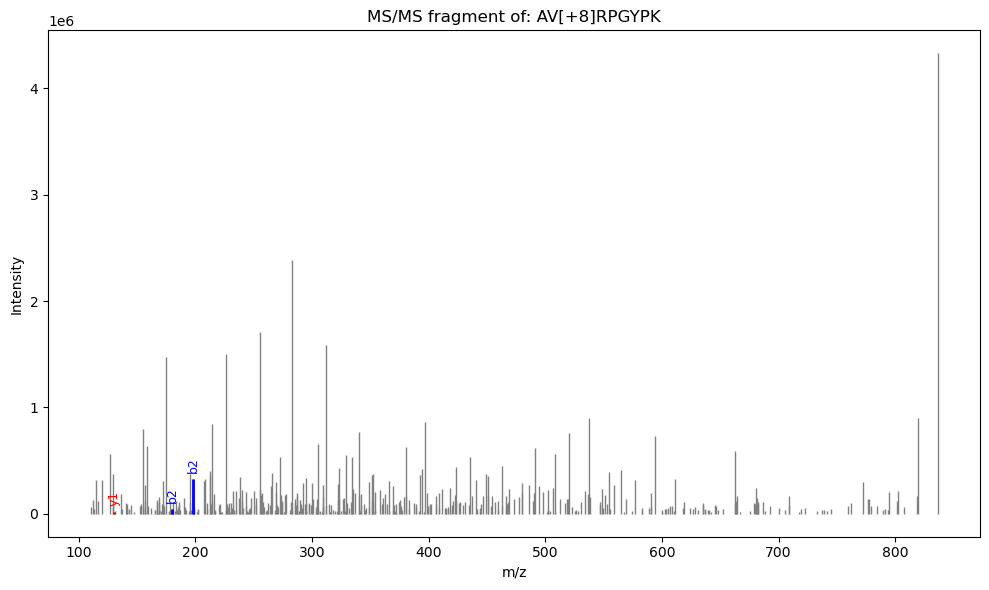

In [71]:
# Creates a plot matching the experimental data with the theoretical fragment ions
fig, ax = plt.subplots(figsize=(10, 6))
ax.vlines(experimental_data["m/z"],0,experimental_data["intensity"],color="gray",linewidth=1)# Plot all experimental peaks in grey

for ion_type, index, mz, intensity, theo_mz in matches:# Plot matched fragment ions and mark them in the spectrum in a certain color and adds a certain label to the fragments
    if ion_type.startswith("b"):
        color = "blue"
        ion_label = f"b{index}"
    elif ion_type.startswith("y"):
        color = "red"
        ion_label = f"y{index}"
    elif ion_type.startswith("a"):
        color = "green"
        ion_label = f"a{index}"
    elif ion_type.startswith("x"):
        color = "purple"
        ion_label = f"x{index}"
    else:
        color = "darkgrey"
        main_ion = ion_type.split("-")[0]
        ion_label = f"{main_ion}{index}-H2O"

    ax.vlines(mz,0,intensity,color=color,linewidth=2)
    ax.text(mz,intensity + max(experimental_data["intensity"]) * 0.02, ion_label, color=color,ha="center",rotation=90,fontsize=9)

matches_pre = [(mz, experimental_data["intensity"][i])for i, mz in enumerate(experimental_data["m/z"]) if abs(mz - peptide_mass) <= 1.0]#Looks for the precursor mass in the experimental data and stores it in a list

if matches_pre:# Mark precursor
    mz_pre, intensity_pre = max(matches_pre, key=lambda x: x[1])
    ax.vlines(mz_pre,0,intensity_pre,color="black",linewidth=2)
    ax.text(mz_pre,intensity_pre + max(experimental_data["intensity"]) * 0.02,"Precursor",color="black",ha="center",rotation=90)

ax.set_xlabel("m/z")
ax.set_ylabel("Intensity")
ax.set_title(f"MS/MS fragment of: {sequence}")

plt.tight_layout()
plt.show()